# NFL Big Data Bowl 2026 — Prediction: Exploratory Data Analysis



In [1]:
from pathlib import Path
import re
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle
from IPython.display import display

RANDOM_SEED = 55
rng = np.random.default_rng(RANDOM_SEED)
FPS = 10  # Official tracking rate: 10 frames / second

plt.rcParams.update({
    "figure.figsize": (10, 5),
    "figure.dpi": 110,
    "axes.grid": True,
    "grid.alpha": 0.25,
    "axes.spines.top": False,
    "axes.spines.right": False,
})
pd.set_option("display.max_columns", 35)
pd.set_option("display.width", 130)
print("pandas:", pd.__version__, "| NumPy:", np.__version__)

pandas: 3.0.1 | NumPy: 2.4.3


In [2]:
# EDIT THIS PATH. It may point either to the extracted competition folder or to train/.
DATA_DIR = Path("./nfl-big-data-bowl-2026-prediction")

# First run: start with three weeks; later set to None for all available weeks.
WEEKS_TO_LOAD = None  # or None

SAVE_FIGURES = True
FIG_DIR = Path("eda_figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

TRAIN_DIR = DATA_DIR / "train" if (DATA_DIR / "train").is_dir() else DATA_DIR

def save_figure(fig, filename):
    if SAVE_FIGURES:
        target = FIG_DIR / filename
        fig.savefig(target, dpi=170, bbox_inches="tight")
        print(f"Saved: {target.resolve()}")

print("Searching:", TRAIN_DIR)
print("Figures directory:", FIG_DIR.resolve())

Searching: nfl-big-data-bowl-2026-prediction/train
Figures directory: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures


 ### Discover and match input/output files



In [3]:
input_files = {
    int(match.group(1)): p
    for p in sorted(TRAIN_DIR.glob("input_2023_w*.csv"))
    if (match := re.fullmatch(r"input_2023_w(\d{2})\.csv", p.name))
}
output_files = {
    int(match.group(1)): p
    for p in sorted(TRAIN_DIR.glob("output_2023_w*.csv"))
    if (match := re.fullmatch(r"output_2023_w(\d{2})\.csv", p.name))
}

if not input_files or not output_files:
    raise FileNotFoundError(
        f"Could not find 2023 weekly input/output files in {TRAIN_DIR}. "
        "Edit DATA_DIR in Code chunk 2 after extracting the Kaggle ZIP."
    )

available_weeks = sorted(set(input_files).intersection(output_files))
missing_pairs = sorted(set(input_files).symmetric_difference(output_files))
if missing_pairs:
    warnings.warn(f"Weeks missing a matching input/output file: {missing_pairs}")

selected_weeks = available_weeks if WEEKS_TO_LOAD is None else [
    w for w in WEEKS_TO_LOAD if w in available_weeks
]
if not selected_weeks:
    raise ValueError(f"None of WEEKS_TO_LOAD={WEEKS_TO_LOAD} has a complete pair. Available: {available_weeks}")

manifest = pd.DataFrame({
    "week": selected_weeks,
    "input_path": [str(input_files[w]) for w in selected_weeks],
    "output_path": [str(output_files[w]) for w in selected_weeks],
})
display(manifest)
print("Weeks selected:", selected_weeks, "| All paired weeks found:", available_weeks)

,week,input_path,output_path
0,1,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
1,2,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
2,3,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
3,4,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
4,5,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
5,6,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
6,7,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
7,8,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
8,9,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...
9,10,nfl-big-data-bowl-2026-prediction/train/input_...,nfl-big-data-bowl-2026-prediction/train/output...


Weeks selected: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18] | All paired weeks found: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]


## Read weekly tracking tables


In [4]:
input_parts, output_parts = [], []
for w in selected_weeks:
    x = pd.read_csv(input_files[w], low_memory=False)
    y = pd.read_csv(output_files[w], low_memory=False)
    x["week"] = w
    y["week"] = w
    input_parts.append(x)
    output_parts.append(y)
    print(f"Week {w:02d}: {len(x):,} input rows; {len(y):,} output rows")

input_df = pd.concat(input_parts, ignore_index=True)
output_df = pd.concat(output_parts, ignore_index=True)
del input_parts, output_parts

REQ_IN = {
    "week", "game_id", "play_id", "nfl_id", "frame_id", "x", "y", "s", "a", "dir",
    "player_to_predict", "player_role", "player_side", "num_frames_output", "ball_land_x", "ball_land_y",
}
REQ_OUT = {"week", "game_id", "play_id", "nfl_id", "frame_id", "x", "y"}
for name, df, required in (("input", input_df, REQ_IN), ("output", output_df, REQ_OUT)):
    missing = sorted(required - set(df.columns))
    if missing:
        raise ValueError(f"Missing required {name} columns: {missing}. Review the dataset/version.")

#Convert potentially string-encoded booleans to a bool column.
input_df["player_to_predict"] = (
    input_df["player_to_predict"].astype(str).str.strip().str.lower().isin(["true", "1", "yes"])
)

for name, df in (("Input", input_df), ("Output", output_df)):
    print(f"\n{name}: {df.shape[0]:,} rows × {df.shape[1]} columns")
    print(f"Approximate pandas memory: {df.memory_usage(deep=True).sum()/1024**2:.1f} MiB")
    display(df.head(3))

Week 01: 285,714 input rows; 32,088 output rows
Week 02: 288,586 input rows; 32,180 output rows
Week 03: 297,757 input rows; 36,080 output rows
Week 04: 272,475 input rows; 30,147 output rows
Week 05: 254,779 input rows; 29,319 output rows
Week 06: 270,676 input rows; 31,162 output rows
Week 07: 233,597 input rows; 27,443 output rows
Week 08: 281,011 input rows; 33,017 output rows
Week 09: 252,796 input rows; 28,291 output rows
Week 10: 260,372 input rows; 29,008 output rows
Week 11: 243,413 input rows; 27,623 output rows
Week 12: 294,940 input rows; 32,156 output rows
Week 13: 233,755 input rows; 29,568 output rows
Week 14: 279,972 input rows; 32,873 output rows
Week 15: 281,820 input rows; 32,715 output rows
Week 16: 316,417 input rows; 36,508 output rows
Week 17: 277,582 input rows; 33,076 output rows
Week 18: 254,917 input rows; 29,682 output rows

Input: 4,880,579 rows × 24 columns
Approximate pandas memory: 2461.6 MiB


,game_id,play_id,player_to_predict,nfl_id,frame_id,play_direction,absolute_yardline_number,player_name,player_height,player_weight,player_birth_date,player_position,player_side,player_role,x,y,s,a,dir,o,num_frames_output,ball_land_x,ball_land_y,week
0,2023090700,101,False,54527,1,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.94,0.09,0.39,322.40,238.24,21,63.259998,-0.22,1
1,2023090700,101,False,54527,2,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.94,0.04,0.61,200.89,236.05,21,63.259998,-0.22,1
2,2023090700,101,False,54527,3,right,42,Bryan Cook,6-1,210,1999-09-07,FS,Defense,Defensive Coverage,52.33,36.93,0.12,0.73,147.55,240.60,21,63.259998,-0.22,1



Output: 562,936 rows × 7 columns
Approximate pandas memory: 30.1 MiB


,game_id,play_id,nfl_id,frame_id,x,y,week
0,2023090700,101,46137,1,56.22,17.28,1
1,2023090700,101,46137,2,56.63,16.88,1
2,2023090700,101,46137,3,57.06,16.46,1


## Inspect and check for duplicate keys

In [5]:
PLAYER_KEYS = ["week", "game_id", "play_id", "nfl_id"]
PLAY_KEYS = ["week", "game_id", "play_id"]
FRAME_KEYS = PLAYER_KEYS + ["frame_id"]

def schema_report(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "missing_pct": (df.isna().mean() * 100).round(2),
        "n_unique": df.nunique(dropna=True),
    }).sort_values("missing_pct", ascending=False)

print("INPUT SCHEMA")
display(schema_report(input_df))
print("OUTPUT SCHEMA")
display(schema_report(output_df))

print("Unique games:", input_df[["week", "game_id"]].drop_duplicates().shape[0])
print("Unique plays:", input_df[PLAY_KEYS].drop_duplicates().shape[0])
print("Unique input player sequences:", input_df[PLAYER_KEYS].drop_duplicates().shape[0])
print("Unique output player sequences:", output_df[PLAYER_KEYS].drop_duplicates().shape[0])
print("Duplicate input frame keys:", int(input_df.duplicated(FRAME_KEYS).sum()))
print("Duplicate output frame keys:", int(output_df.duplicated(FRAME_KEYS).sum()))

if input_df.duplicated(FRAME_KEYS).any() or output_df.duplicated(FRAME_KEYS).any():
    raise ValueError("Duplicate tracking keys detected; inspect them before merging or scoring.")

INPUT SCHEMA


,dtype,missing_count,missing_pct,n_unique
game_id,int64,0,0.0,272
play_id,int64,0,0.0,4317
player_to_predict,bool,0,0.0,2
nfl_id,int64,0,0.0,1384
frame_id,int64,0,0.0,123
play_direction,str,0,0.0,2
absolute_yardline_number,int64,0,0.0,99
player_name,str,0,0.0,1383
player_height,str,0,0.0,16
player_weight,int64,0,0.0,151


OUTPUT SCHEMA


,dtype,missing_count,missing_pct,n_unique
game_id,int64,0,0.0,272
play_id,int64,0,0.0,4317
nfl_id,int64,0,0.0,1178
frame_id,int64,0,0.0,94
x,float64,0,0.0,11894
y,float64,0,0.0,5260
week,int64,0,0.0,18


Unique games: 272
Unique plays: 14108
Unique input player sequences: 173150
Unique output player sequences: 46045
Duplicate input frame keys: 0
Duplicate output frame keys: 0


## Looking for missing values

Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/01_missing_values.png


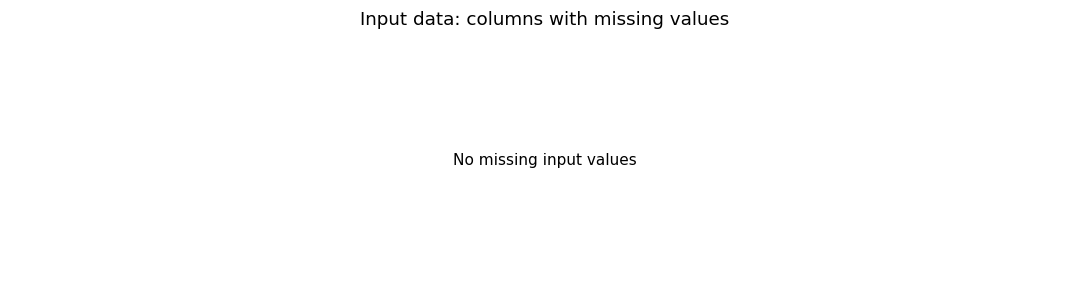

player_to_predict,Not scored,Scored
player_role,,
Defensive Coverage,62356,31937
Other Route Runner,50644,0
Passer,14105,0
Targeted Receiver,0,14108


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/02_role_prediction_counts.png


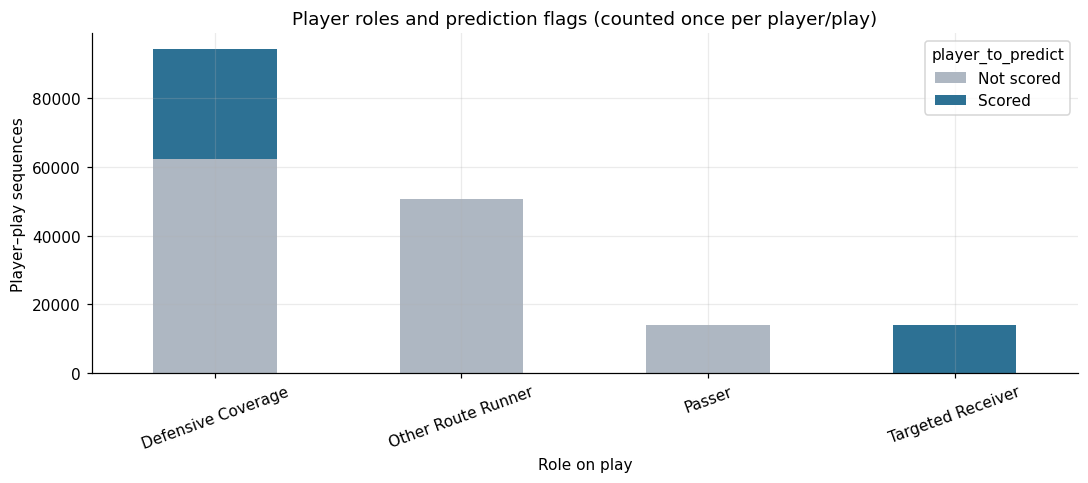

In [6]:
missing_pct = (input_df.isna().mean() * 100).sort_values(ascending=False)
top_missing = missing_pct[missing_pct > 0].head(14)
fig, ax = plt.subplots(figsize=(10, max(2.8, 0.38 * max(1, len(top_missing)))))
if len(top_missing):
    top_missing.sort_values().plot.barh(ax=ax, color="#597da3")
    ax.set_xlabel("Missing values (% of input rows)")
else:
    ax.text(0.5, 0.5, "No missing input values", ha="center", va="center", transform=ax.transAxes)
    ax.set_axis_off()
ax.set_title("Input data: columns with missing values")
plt.tight_layout()
save_figure(fig, "01_missing_values.png")
plt.show()

input_sorted = input_df.sort_values(FRAME_KEYS).copy()
last_input = input_sorted.groupby(PLAYER_KEYS, sort=False).tail(1).copy()
role_counts = pd.crosstab(
    last_input["player_role"].fillna("Missing role"),
    last_input["player_to_predict"],
).rename(columns={False: "Not scored", True: "Scored"})
display(role_counts)
ax = role_counts.plot(kind="bar", stacked=True, figsize=(10, 4.5), rot=20,
                      color=["#aeb7c2", "#2d7194"][:len(role_counts.columns)])
ax.set_ylabel("Player–play sequences")
ax.set_xlabel("Role on play")
ax.set_title("Player roles and prediction flags (counted once per player/play)")
plt.tight_layout()
save_figure(ax.figure, "02_role_prediction_counts.png")
plt.show()

# Input history and future horizon lengths


Scored player-sequence completeness:


complete_target
True    46045
Name: sequences, dtype: int64


Length summary (frames):


,input_frames,num_frames_output,actual_output_frames
count,46045.000000,46045.000000,46045.000000
mean,28.307960,12.225779,12.225779
std,9.115599,5.534126,5.534126
min,8.000000,5.000000,5.000000
25%,22.000000,8.000000,8.000000
50%,27.000000,11.000000,11.000000
75%,33.000000,14.000000,14.000000
max,123.000000,94.000000,94.000000


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/03_sequence_lengths.png


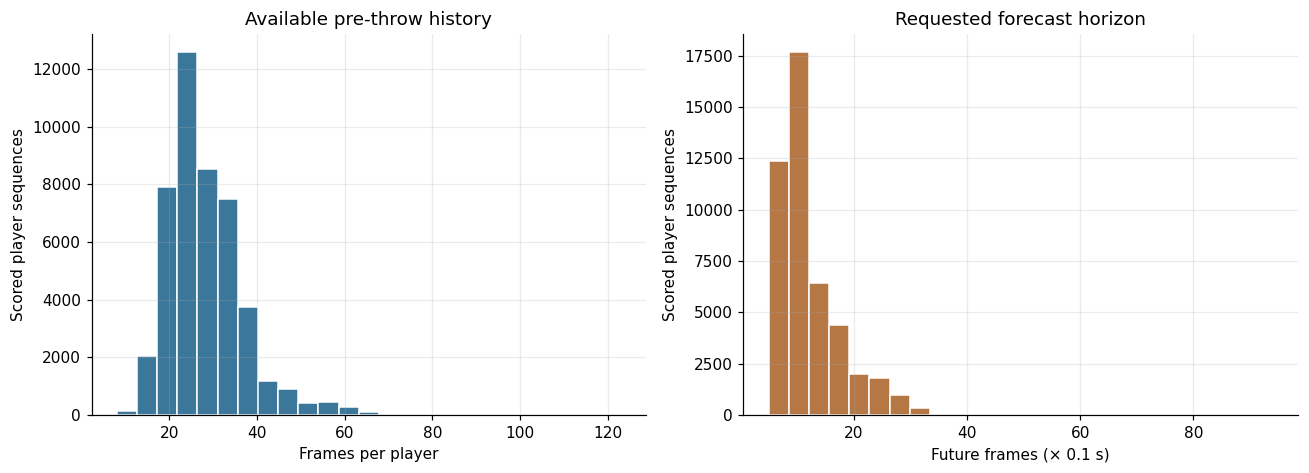

In [7]:
input_lengths = (
    input_sorted.groupby(PLAYER_KEYS, sort=False)
    .agg(input_frames=("frame_id", "nunique"), last_input_frame=("frame_id", "max"))
    .reset_index()
)
input_lengths = input_lengths.merge(
    last_input[PLAYER_KEYS + ["player_role", "player_to_predict", "num_frames_output"]],
    on=PLAYER_KEYS, validate="one_to_one"
)
output_lengths = (
    output_df.groupby(PLAYER_KEYS, sort=False)
    .agg(actual_output_frames=("frame_id", "nunique"), max_output_frame=("frame_id", "max"))
    .reset_index()
)
sequence_lengths = input_lengths.merge(output_lengths, on=PLAYER_KEYS, how="left", validate="one_to_one")
scored_lengths = sequence_lengths.loc[sequence_lengths["player_to_predict"]].copy()
scored_lengths["num_frames_output"] = pd.to_numeric(scored_lengths["num_frames_output"], errors="coerce")
scored_lengths["complete_target"] = (
    (scored_lengths["actual_output_frames"] == scored_lengths["num_frames_output"]) &
    (scored_lengths["max_output_frame"] == scored_lengths["num_frames_output"])
)
print("Scored player-sequence completeness:")
display(scored_lengths["complete_target"].value_counts(dropna=False).rename("sequences"))
print("\nLength summary (frames):")
display(scored_lengths[["input_frames", "num_frames_output", "actual_output_frames"]].describe())

fig, axs = plt.subplots(1, 2, figsize=(12, 4.4))
axs[0].hist(scored_lengths["input_frames"].dropna(), bins=25, color="#3a779b", edgecolor="white")
axs[0].set(title="Available pre-throw history", xlabel="Frames per player", ylabel="Scored player sequences")
axs[1].hist(scored_lengths["num_frames_output"].dropna(), bins=25, color="#b57744", edgecolor="white")
axs[1].set(title="Requested forecast horizon", xlabel="Future frames (× 0.1 s)", ylabel="Scored player sequences")
plt.tight_layout()
save_figure(fig, "03_sequence_lengths.png")
plt.show()

## Visible and scored players per play?


,observed_players,scored_players
count,14108.000000,14108.000000
mean,12.273178,3.263751
std,1.118459,1.312664
min,1.000000,1.000000
25%,12.000000,2.000000
50%,13.000000,3.000000
75%,13.000000,4.000000
max,17.000000,9.000000


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/04_players_per_play.png


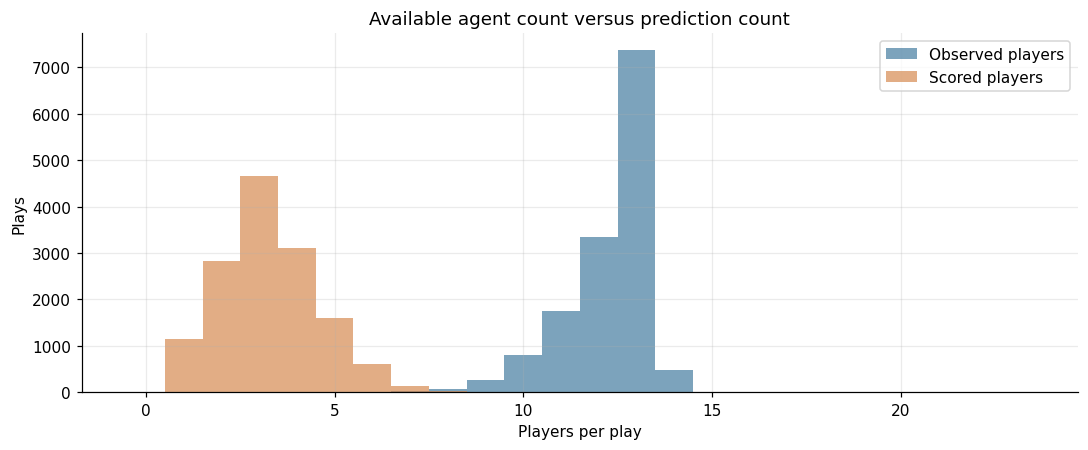

In [8]:
play_player_counts = (
    last_input.groupby(PLAY_KEYS, sort=False)
    .agg(observed_players=("nfl_id", "nunique"), scored_players=("player_to_predict", "sum"))
    .reset_index()
)
display(play_player_counts[["observed_players", "scored_players"]].describe())
fig, ax = plt.subplots(figsize=(10, 4.2))
ax.hist(play_player_counts["observed_players"], bins=np.arange(0, 25) - .5,
        alpha=0.7, label="Observed players", color="#447ca0")
ax.hist(play_player_counts["scored_players"], bins=np.arange(0, 25) - .5,
        alpha=0.7, label="Scored players", color="#d68b52")
ax.set(xlabel="Players per play", ylabel="Plays", title="Available agent count versus prediction count")
ax.legend()
plt.tight_layout()
save_figure(fig, "04_players_per_play.png")
plt.show()

##  Player motion at the time of release


s                           a                     
                    count   mean median    std  count   mean median    std
player_role                                                               
Defensive Coverage  94293  3.939  3.860  1.766  94293  2.452   2.27  1.343
Targeted Receiver   14108  5.570  5.805  1.922  14108  3.065   2.97  1.614

Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/05_release_motion_by_role.png


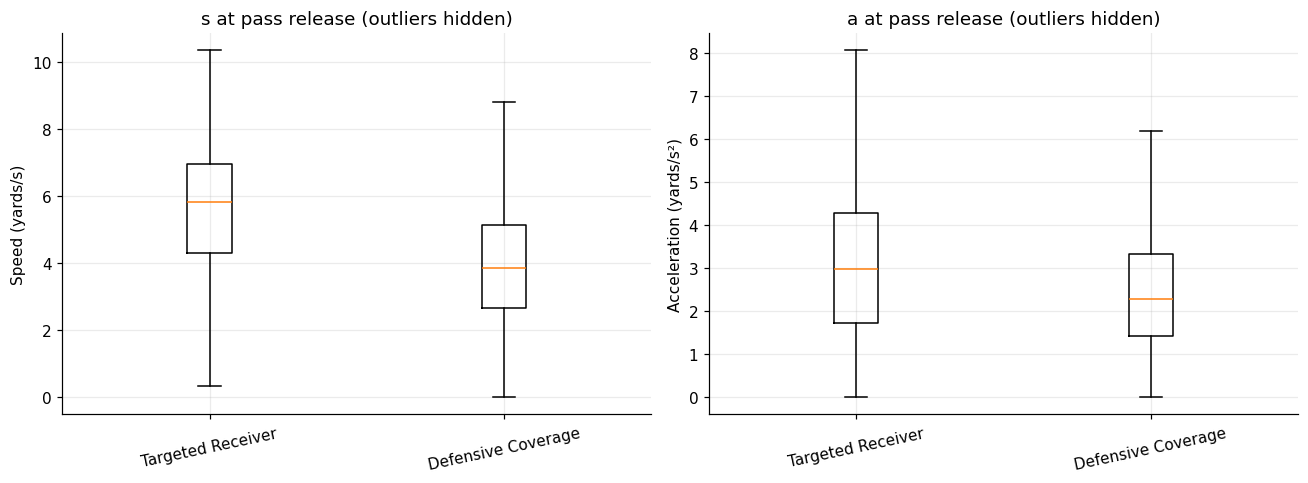

In [9]:
focus_roles = ["Targeted Receiver", "Defensive Coverage"]
motion = last_input[last_input["player_role"].isin(focus_roles)].copy()
for c in ["s", "a"]:
    motion[c] = pd.to_numeric(motion[c], errors="coerce")
display(motion.groupby("player_role")[["s", "a"]].agg(["count", "mean", "median", "std"]).round(3))

fig, axs = plt.subplots(1, 2, figsize=(12, 4.5))
for ax, col, ylabel in zip(axs, ["s", "a"], ["Speed (yards/s)", "Acceleration (yards/s²)"]):
    groups = [motion.loc[motion["player_role"] == r, col].dropna().values for r in focus_roles]
    ax.boxplot(groups, tick_labels=focus_roles, showfliers=False)
    ax.set(ylabel=ylabel, title=f"{col} at pass release (outliers hidden)")
    ax.tick_params(axis="x", rotation=12)
plt.tight_layout()
save_figure(fig, "05_release_motion_by_role.png")
plt.show()

## Making a field visual

In [10]:
# Optional explicit choice: provide both game and play ID, or leave as None.
EXAMPLE_GAME_ID = None
EXAMPLE_PLAY_ID = None

receiver_plays = last_input.loc[
    last_input["player_role"].eq("Targeted Receiver") & last_input["player_to_predict"], PLAY_KEYS
].drop_duplicates()
if EXAMPLE_GAME_ID is None or EXAMPLE_PLAY_ID is None:
    candidates = receiver_plays if not receiver_plays.empty else last_input[PLAY_KEYS].drop_duplicates()
    chosen = candidates.iloc[int(rng.integers(len(candidates)))]
else:
    candidates = last_input.loc[
        last_input["game_id"].eq(EXAMPLE_GAME_ID) & last_input["play_id"].eq(EXAMPLE_PLAY_ID), PLAY_KEYS
    ].drop_duplicates()
    if candidates.empty:
        raise ValueError("Selected game/play does not appear in the loaded weeks.")
    chosen = candidates.iloc[0]
example_week, example_game, example_play = (int(chosen[k]) for k in PLAY_KEYS)

play_in = input_sorted.loc[
    input_sorted["week"].eq(example_week) & input_sorted["game_id"].eq(example_game) & input_sorted["play_id"].eq(example_play)
].copy()
play_out = output_df.loc[
    output_df["week"].eq(example_week) & output_df["game_id"].eq(example_game) & output_df["play_id"].eq(example_play)
].copy()
print(f"Example: week {example_week}, game {example_game}, play {example_play}")
print(f"Observed players: {play_in['nfl_id'].nunique()} | Output players: {play_out['nfl_id'].nunique()}")

def draw_field(ax):
    ax.set_facecolor("#f5faf3")
    ax.add_patch(Rectangle((0, 0), 120, 53.3, color="#e4f0e2", zorder=0))
    ax.add_patch(Rectangle((0, 0), 10, 53.3, color="#cbdcce", alpha=.75, zorder=0))
    ax.add_patch(Rectangle((110, 0), 10, 53.3, color="#cbdcce", alpha=.75, zorder=0))
    for xline in range(10, 111, 10):
        ax.axvline(xline, color="white", linewidth=1.5, zorder=1)
    ax.set_xlim(0, 120)
    ax.set_ylim(0, 53.3)
    ax.set_aspect("equal", adjustable="box")
    ax.set(xlabel="Field x (yards)", ylabel="Field y (yards)")
    ax.grid(False)

Example: week 18, game 2024010703, play 1684
Observed players: 12 | Output players: 2


## Plot listed and future player trajectories


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/06_example_player_trajectories.png


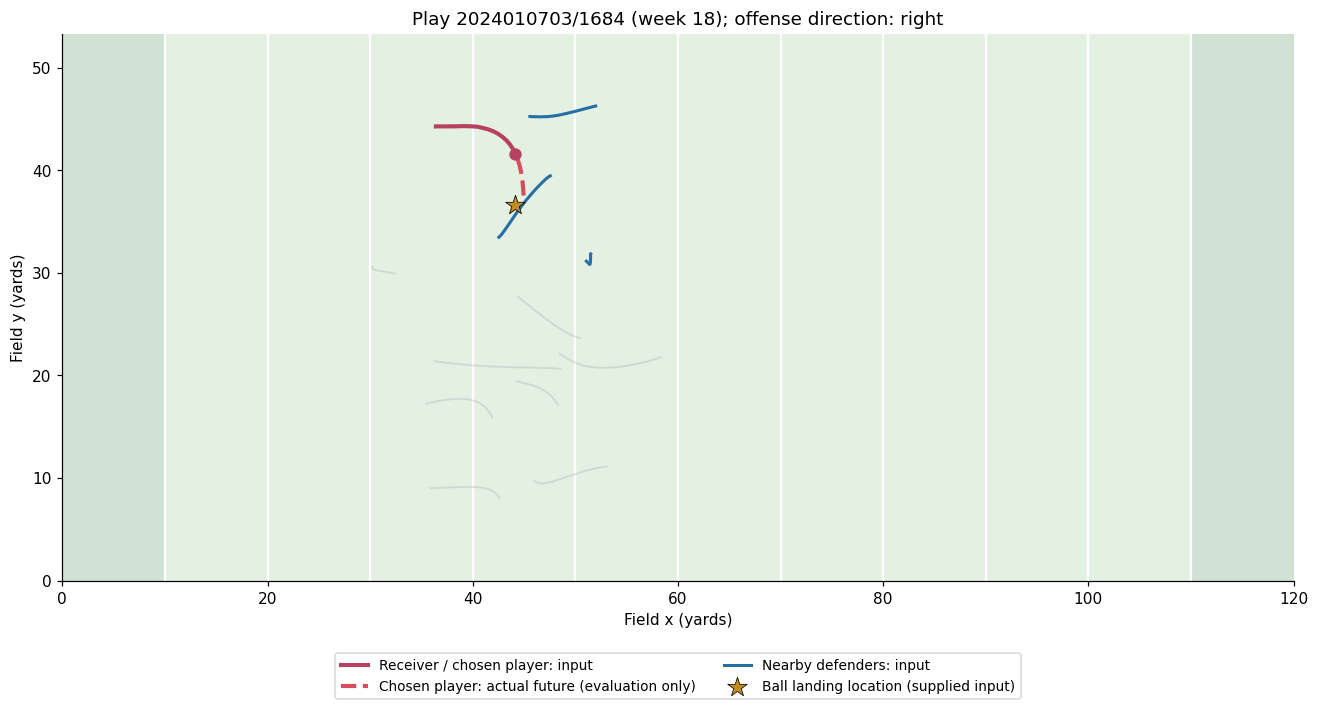

In [11]:
def plot_example_play(play_in, play_out):
    fig, ax = plt.subplots(figsize=(13, 6.2))
    draw_field(ax)
    for _, track in play_in.sort_values("frame_id").groupby("nfl_id"):
        ax.plot(track["x"], track["y"], color="#9da7af", alpha=.32, linewidth=1.2)
    recent = play_in.sort_values("frame_id").groupby("nfl_id").tail(1)
    rec = recent.loc[recent["player_role"].eq("Targeted Receiver") & recent["player_to_predict"]]
    if rec.empty:
        rec = recent.loc[recent["player_to_predict"]]
    rec = rec.iloc[0] if len(rec) else recent.iloc[0]
    rec_id = rec["nfl_id"]
    rec_track = play_in.loc[play_in["nfl_id"].eq(rec_id)].sort_values("frame_id")
    ax.plot(rec_track["x"], rec_track["y"], color="#b64160", linewidth=2.7, label="Receiver / chosen player: input")
    ax.scatter([rec["x"]], [rec["y"]], color="#b64160", s=50, zorder=5)
    rec_future = play_out.loc[play_out["nfl_id"].eq(rec_id)].sort_values("frame_id")
    if not rec_future.empty:
        ax.plot(rec_future["x"], rec_future["y"], "--", linewidth=2.7,
                color="#d94c5e", label="Chosen player: actual future (evaluation only)")
    defenses = recent.loc[recent["player_role"].eq("Defensive Coverage")].copy()
    if not defenses.empty:
        defenses["dist"] = np.hypot(defenses["x"] - rec["x"], defenses["y"] - rec["y"])
        for j, defender_id in enumerate(defenses.nsmallest(3, "dist")["nfl_id"]):
            track = play_in.loc[play_in["nfl_id"].eq(defender_id)].sort_values("frame_id")
            ax.plot(track["x"], track["y"], linewidth=2, color="#256fa4",
                    label="Nearby defenders: input" if j == 0 else None)
    if pd.notna(rec["ball_land_x"]) and pd.notna(rec["ball_land_y"]):
        ax.scatter([rec["ball_land_x"]], [rec["ball_land_y"]], marker="*", s=180,
                   color="#c38c20", edgecolors="black", linewidths=.5,
                   label="Ball landing location (supplied input)", zorder=6)
    direction = rec.get("play_direction", "unknown")
    ax.set_title(f"Play {example_game}/{example_play} (week {example_week}); offense direction: {direction}")
    ax.legend(loc="upper center", bbox_to_anchor=(.5, -.12), ncol=2, fontsize=9)
    plt.tight_layout()
    return fig, rec_id

example_fig, example_receiver_id = plot_example_play(play_in, play_out)
save_figure(example_fig, "06_example_player_trajectories.png")
plt.show()

## Timeline view of a player's x/y coordinates


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/07_example_trajectory_timeseries.png


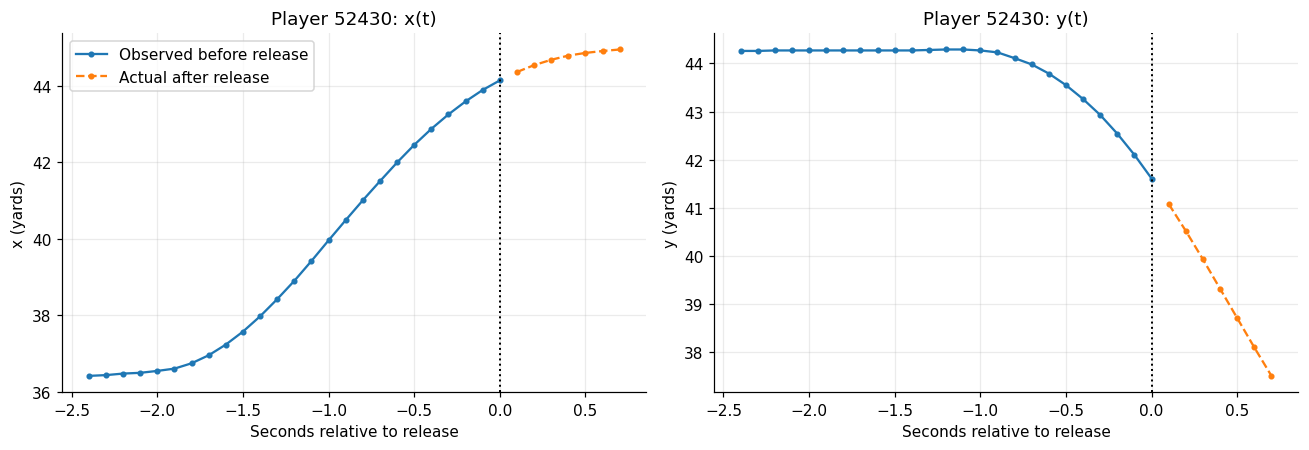

In [12]:
hist = play_in.loc[play_in["nfl_id"].eq(example_receiver_id)].sort_values("frame_id").copy()
futr = play_out.loc[play_out["nfl_id"].eq(example_receiver_id)].sort_values("frame_id").copy()
hist["relative_t_s"] = (hist["frame_id"] - hist["frame_id"].max()) / FPS
futr["relative_t_s"] = futr["frame_id"] / FPS
fig, axs = plt.subplots(1, 2, figsize=(12, 4.2))
for ax, col in zip(axs, ["x", "y"]):
    ax.plot(hist["relative_t_s"], hist[col], "o-", markersize=3, label="Observed before release")
    if not futr.empty:
        ax.plot(futr["relative_t_s"], futr[col], "o--", markersize=3, label="Actual after release")
    ax.axvline(0, color="black", linestyle=":", linewidth=1.3)
    ax.set(xlabel="Seconds relative to release", ylabel=f"{col} (yards)", title=f"Player {example_receiver_id}: {col}(t)")
axs[0].legend()
plt.tight_layout()
save_figure(fig, "07_example_trajectory_timeseries.png")
plt.show()

## Nearest-defender distance at time of release

Targeted receivers with >=1 defensive coverage player: 14107


,distance (yards)
count,14107.000000
mean,4.414296
std,3.243596
min,0.222036
25%,1.938582
50%,3.643295
75%,5.890093
max,25.352919


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/08_receiver_defender_separation.png


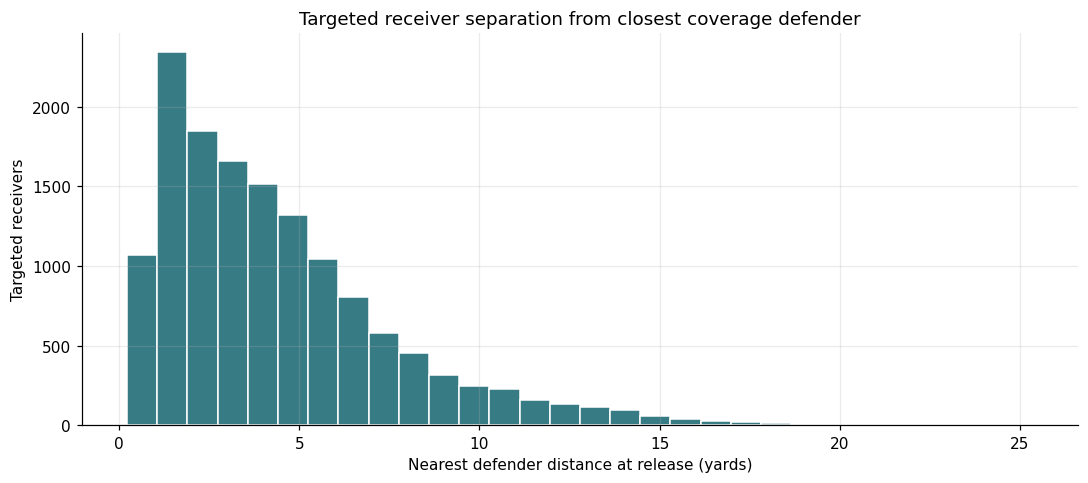

In [13]:
def nearest_defender_features(last_positions):
    records = []
    for keys, players in last_positions.groupby(PLAY_KEYS, sort=False):
        receivers = players.loc[players["player_role"].eq("Targeted Receiver") & players["player_to_predict"]]
        defenders = players.loc[players["player_role"].eq("Defensive Coverage")]
        if receivers.empty or defenders.empty:
            continue
        D = defenders[["x", "y"]].to_numpy(dtype=float)
        dids = defenders["nfl_id"].to_numpy()
        for r in receivers.itertuples(index=False):
            distances = np.hypot(D[:, 0] - r.x, D[:, 1] - r.y)
            if not np.isfinite(distances).any():
                continue
            ix = int(np.nanargmin(distances))
            records.append({
                **dict(zip(PLAY_KEYS, keys)),
                "nfl_id": r.nfl_id,
                "nearest_defender_id": dids[ix],
                "nearest_defender_yards": float(distances[ix]),
                "num_coverage_defenders": len(defenders),
            })
    return pd.DataFrame.from_records(records, columns=PLAYER_KEYS + [
        "nearest_defender_id", "nearest_defender_yards", "num_coverage_defenders"
    ])

receiver_separation = nearest_defender_features(last_input)
print("Targeted receivers with >=1 defensive coverage player:", len(receiver_separation))
display(receiver_separation["nearest_defender_yards"].describe().to_frame("distance (yards)"))
fig, ax = plt.subplots(figsize=(10, 4.5))
ax.hist(receiver_separation["nearest_defender_yards"].dropna(), bins=30,
        color="#377c85", edgecolor="white")
ax.set(xlabel="Nearest defender distance at release (yards)", ylabel="Targeted receivers",
       title="Targeted receiver separation from closest coverage defender")
plt.tight_layout()
save_figure(fig, "08_receiver_defender_separation.png")
plt.show()

## Baselines

In [14]:
# Compute previous OBSERVED input row per player; frame gaps are handled explicitly.
previous = input_sorted.groupby(PLAYER_KEYS, sort=False)[["x", "y", "frame_id"]].shift(1)
previous.columns = ["prev_x", "prev_y", "prev_frame_id"]
input_with_prev = pd.concat([input_sorted, previous], axis=1)
release = input_with_prev.groupby(PLAYER_KEYS, sort=False).tail(1).copy()
release = release.loc[release["player_to_predict"]].copy()
release["frame_gap"] = release["frame_id"] - release["prev_frame_id"]
valid_history = (
    release["prev_x"].notna() & release["prev_y"].notna() & release["frame_gap"].gt(0)
)
release["vx_per_frame"] = np.where(
    valid_history, (release["x"] - release["prev_x"]) / release["frame_gap"], 0.0
)
release["vy_per_frame"] = np.where(
    valid_history, (release["y"] - release["prev_y"]) / release["frame_gap"], 0.0
)
release = release.rename(columns={
    "x": "release_x", "y": "release_y", "frame_id": "release_frame_id",
})
release_cols = PLAYER_KEYS + ["player_role", "player_side", "release_x", "release_y",
                              "release_frame_id", "vx_per_frame", "vy_per_frame",
                              "num_frames_output", "ball_land_x", "ball_land_y"]
scoring = output_df.merge(
    release[release_cols], on=PLAYER_KEYS, how="inner", validate="many_to_one"
)
if scoring.empty:
    raise ValueError("No output frames matched scored player sequences. Inspect IDs and files.")
# Output frame_id starts again at 1; relative to last input step 0, future displacement uses k frames.
k = scoring["frame_id"].to_numpy(dtype=float)
scoring["last_x"] = scoring["release_x"]
scoring["last_y"] = scoring["release_y"]
scoring["cv_x"] = scoring["release_x"] + k * scoring["vx_per_frame"]
scoring["cv_y"] = scoring["release_y"] + k * scoring["vy_per_frame"]

print(f"Scored output frames matched: {len(scoring):,} / {len(output_df):,} total output rows")
print("Scored player sequences lacking two valid observed frames:", int((~valid_history).sum()))
display(scoring[["week", "game_id", "play_id", "nfl_id", "frame_id",
                 "x", "y", "last_x", "last_y", "cv_x", "cv_y"]].head(6))

Scored output frames matched: 562,936 / 562,936 total output rows
Scored player sequences lacking two valid observed frames: 0


,week,game_id,play_id,nfl_id,frame_id,x,y,last_x,last_y,cv_x,cv_y
0,1,2023090700,101,46137,1,56.22,17.28,55.82,17.67,56.19,17.31
1,1,2023090700,101,46137,2,56.63,16.88,55.82,17.67,56.56,16.95
2,1,2023090700,101,46137,3,57.06,16.46,55.82,17.67,56.93,16.59
3,1,2023090700,101,46137,4,57.48,16.02,55.82,17.67,57.30,16.23
4,1,2023090700,101,46137,5,57.91,15.56,55.82,17.67,57.67,15.87
5,1,2023090700,101,46137,6,58.34,15.10,55.82,17.67,58.04,15.51


## RMSE, ADE, and FDE

In [15]:
for model, xc, yc in [("last", "last_x", "last_y"), ("cv", "cv_x", "cv_y")]:
    scoring[f"sqerr_{model}"] = (scoring[xc] - scoring["x"])**2 + (scoring[yc] - scoring["y"])**2
    scoring[f"dist_{model}"] = np.sqrt(scoring[f"sqerr_{model}"])

def evaluate_subset(df):
    if df.empty:
        return pd.DataFrame(columns=["baseline", "RMSE_yards", "ADE_yards", "FDE_yards", "frames", "player_sequences"])
    final_rows = df.sort_values("frame_id").groupby(PLAYER_KEYS, sort=False).tail(1)
    rows = []
    for baseline in ["last", "cv"]:
        rows.append({
            "baseline": "Last position" if baseline == "last" else "Constant velocity",
            "RMSE_yards": np.sqrt(df[f"sqerr_{baseline}"].mean() / 2),
            "ADE_yards": df[f"dist_{baseline}"].mean(),
            "FDE_yards": final_rows[f"dist_{baseline}"].mean(),
            "frames": len(df),
            "player_sequences": len(final_rows),
        })
    return pd.DataFrame(rows)

baseline_metrics = evaluate_subset(scoring)
display(baseline_metrics.round(4))
print("Note: Baselines have not been trained or optimized; these are descriptive reference results.")

,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,Last position,4.2437,4.2467,6.2544,562936,46045
1,Constant velocity,1.7626,1.4859,2.7987,562936,46045


Note: Baselines have not been trained or optimized; these are descriptive reference results.


## forecasting error by player role

,role,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
1,Defensive Coverage,Constant velocity,1.864,1.592,3.041,402576,31937
0,Defensive Coverage,Last position,4.047,4.052,6.101,402576,31937
3,Targeted Receiver,Constant velocity,1.479,1.219,2.251,160360,14108
2,Targeted Receiver,Last position,4.701,4.735,6.601,160360,14108


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/09_baseline_rmse_by_role.png


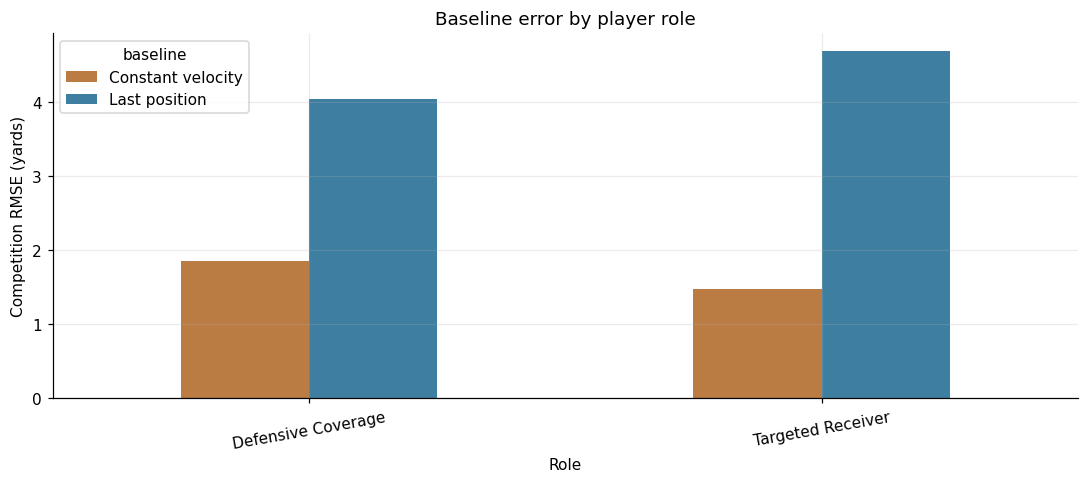

In [16]:
role_results = []
for role, subset in scoring.groupby("player_role", dropna=False):
    result = evaluate_subset(subset)
    result.insert(0, "role", role)
    role_results.append(result)
role_metrics = pd.concat(role_results, ignore_index=True)
display(role_metrics.sort_values(["role", "baseline"]).round(3))

plot_roles = role_metrics[role_metrics["role"].isin(focus_roles)]
if not plot_roles.empty:
    pivot = plot_roles.pivot(index="role", columns="baseline", values="RMSE_yards")
    ax = pivot.plot.bar(rot=10, figsize=(10, 4.5), color=["#bb7c43", "#3d7ea1"])
    ax.set(ylabel="Competition RMSE (yards)", xlabel="Role", title="Baseline error by player role")
    plt.tight_layout()
    save_figure(ax.figure, "09_baseline_rmse_by_role.png")
    plt.show()

## Error as forecast horizon increases

Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/10_error_by_forecast_horizon.png


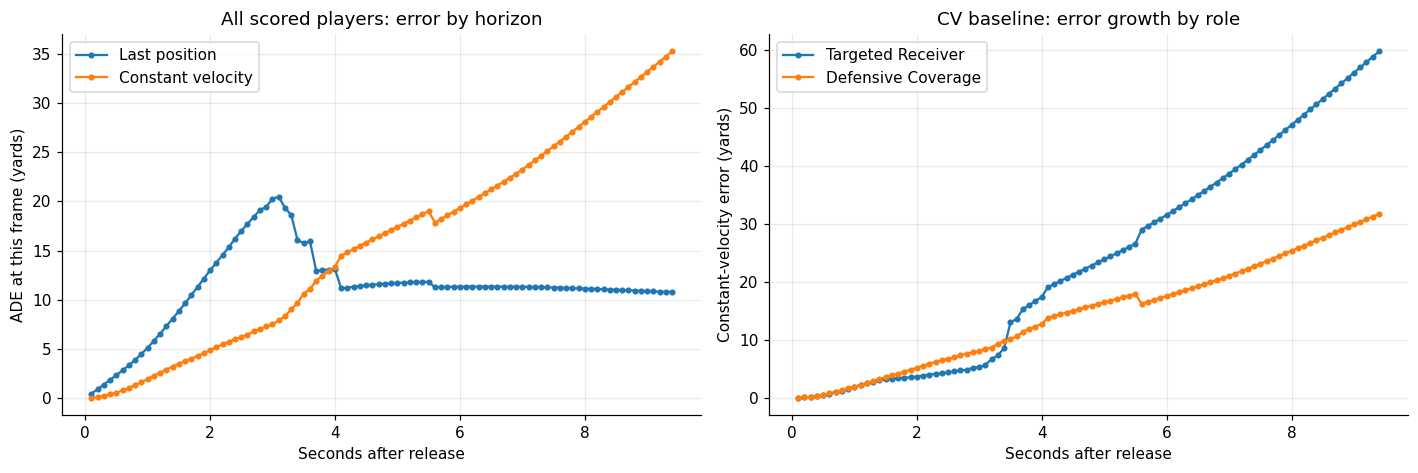

In [17]:
horizon_summary = (
    scoring.groupby("frame_id", sort=True)[["dist_last", "dist_cv"]]
    .agg(["mean", "count"])
)
fig, axs = plt.subplots(1, 2, figsize=(13, 4.4))
for name, column in [("Last position", "dist_last"), ("Constant velocity", "dist_cv")]:
    means = scoring.groupby("frame_id")[column].mean()
    axs[0].plot(means.index / FPS, means.values, marker=".", label=name)
axs[0].set(xlabel="Seconds after release", ylabel="ADE at this frame (yards)",
           title="All scored players: error by horizon")
axs[0].legend()
for role in focus_roles:
    part = scoring[scoring["player_role"].eq(role)]
    means = part.groupby("frame_id")["dist_cv"].mean()
    if len(means):
        axs[1].plot(means.index / FPS, means.values, marker=".", label=role)
axs[1].set(xlabel="Seconds after release", ylabel="Constant-velocity error (yards)",
           title="CV baseline: error growth by role")
axs[1].legend()
plt.tight_layout()
save_figure(fig, "10_error_by_forecast_horizon.png")
plt.show()

## receiver–defender separation relation to error

,separation_bin,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,<2 yd,Last position,5.911,6.311,9.193,51235,3673
1,<2 yd,Constant velocity,1.644,1.509,2.923,51235,3673
2,2–5 yd,Last position,4.560,4.587,6.454,63538,5711
3,2–5 yd,Constant velocity,1.417,1.270,2.415,63538,5711
4,5–10 yd,Last position,3.233,3.294,4.871,36532,3738
5,5–10 yd,Constant velocity,1.489,0.896,1.643,36532,3738
6,>=10 yd,Last position,2.385,2.669,4.352,9041,985
7,>=10 yd,Constant velocity,0.620,0.520,1.099,9041,985


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/11_receiver_proximity_and_error.png


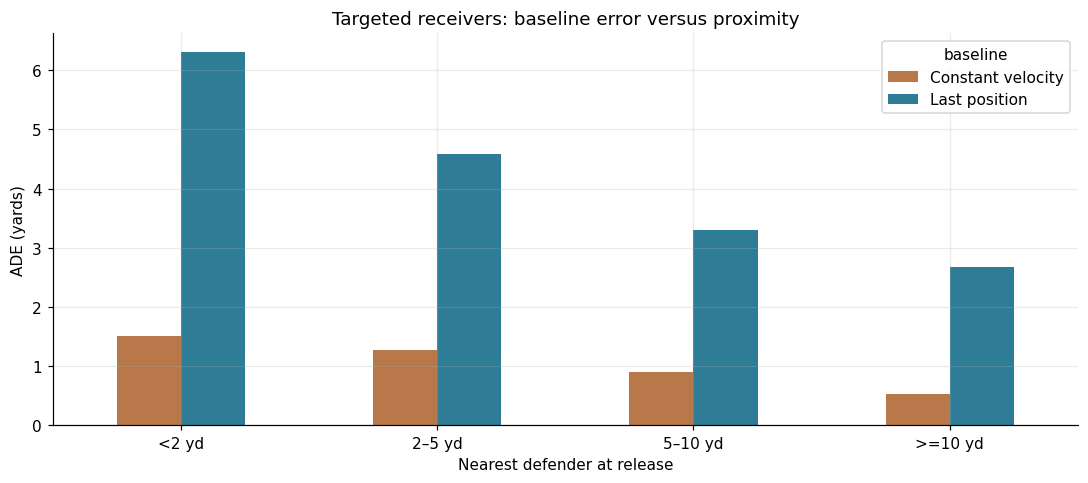

In [18]:
receiver_scored = scoring.loc[scoring["player_role"].eq("Targeted Receiver")].merge(
    receiver_separation[PLAYER_KEYS + ["nearest_defender_yards"]],
    on=PLAYER_KEYS, how="left", validate="many_to_one"
)
bins = [-np.inf, 2.0, 5.0, 10.0, np.inf]
labels = ["<2 yd", "2–5 yd", "5–10 yd", ">=10 yd"]
receiver_scored["separation_bin"] = pd.cut(
    receiver_scored["nearest_defender_yards"], bins=bins, labels=labels, right=False
)
sep_rows = []
for band, part in receiver_scored.groupby("separation_bin", observed=True):
    for _, metric in evaluate_subset(part).iterrows():
        sep_rows.append({"separation_bin": str(band), **metric.to_dict()})
sep_metrics = pd.DataFrame(sep_rows)
if sep_metrics.empty:
    print("No targeted receiver observations with eligible defenders in the selected weeks.")
else:
    display(sep_metrics.round(3))
    pivot = sep_metrics.pivot(index="separation_bin", columns="baseline", values="ADE_yards")
    pivot = pivot.reindex(labels)
    ax = pivot.plot(kind="bar", rot=0, figsize=(10, 4.5), color=["#b87849", "#2f7c96"])
    ax.set(xlabel="Nearest defender at release", ylabel="ADE (yards)",
           title="Targeted receivers: baseline error versus proximity")
    plt.tight_layout()
    save_figure(ax.figure, "11_receiver_proximity_and_error.png")
    plt.show()

## Paired game-level bootstrap comparison 

Observed CV - last-position RMSE: -2.4810 yards
Paired game bootstrap 95% interval: [-2.6051, -2.2869] yards
Game clusters: 272; bootstrap draws: 500
Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/12_game_bootstrap_rmse_difference.png


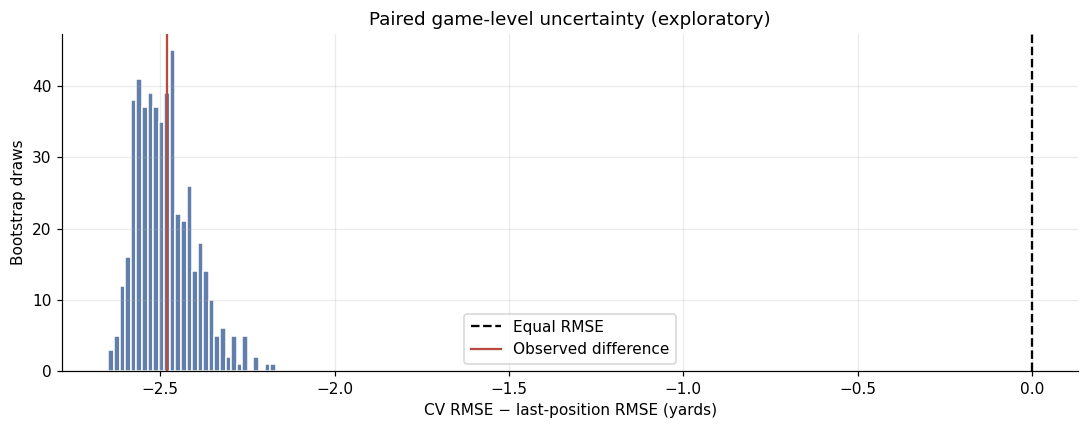

In [19]:
N_BOOTSTRAPS = 500
GAME_KEYS = ["week", "game_id"]
game_sums = (
    scoring.groupby(GAME_KEYS, sort=False)
    .agg(n=("sqerr_last", "size"), last_sq=("sqerr_last", "sum"), cv_sq=("sqerr_cv", "sum"))
    .reset_index()
)
if len(game_sums) < 2:
    print("Bootstrap skipped: need observations from at least two games.")
else:
    per_game = game_sums[["n", "last_sq", "cv_sq"]].to_numpy(dtype=float)
    sample_idx = rng.integers(0, len(per_game), size=(N_BOOTSTRAPS, len(per_game)))
    sampled = per_game[sample_idx].sum(axis=1)
    rmse_last = np.sqrt(sampled[:, 1] / (2 * sampled[:, 0]))
    rmse_cv = np.sqrt(sampled[:, 2] / (2 * sampled[:, 0]))
    delta = rmse_cv - rmse_last
    observed_delta = float(baseline_metrics.loc[baseline_metrics["baseline"].eq("Constant velocity"), "RMSE_yards"].iloc[0] -
                           baseline_metrics.loc[baseline_metrics["baseline"].eq("Last position"), "RMSE_yards"].iloc[0])
    ci_lo, ci_hi = np.quantile(delta, [.025, .975])
    print(f"Observed CV - last-position RMSE: {observed_delta:+.4f} yards")
    print(f"Paired game bootstrap 95% interval: [{ci_lo:+.4f}, {ci_hi:+.4f}] yards")
    print(f"Game clusters: {len(per_game):,}; bootstrap draws: {N_BOOTSTRAPS}")
    fig, ax = plt.subplots(figsize=(10, 4))
    ax.hist(delta, bins=30, color="#627fab", edgecolor="white")
    ax.axvline(0, color="black", linestyle="--", label="Equal RMSE")
    ax.axvline(observed_delta, color="#b54c3f", label="Observed difference")
    ax.set(xlabel="CV RMSE − last-position RMSE (yards)", ylabel="Bootstrap draws",
           title="Paired game-level uncertainty (exploratory)")
    ax.legend()
    plt.tight_layout()
    save_figure(fig, "12_game_bootstrap_rmse_difference.png")
    plt.show()

## Summaries

In [20]:
if SAVE_FIGURES:
    baseline_metrics.to_csv(FIG_DIR / "baseline_metrics.csv", index=False)
    role_metrics.to_csv(FIG_DIR / "role_metrics.csv", index=False)
    sequence_lengths.to_csv(FIG_DIR / "sequence_lengths.csv", index=False)
    receiver_separation.to_csv(FIG_DIR / "receiver_release_separation.csv", index=False)
    if not sep_metrics.empty:
        sep_metrics.to_csv(FIG_DIR / "separation_band_metrics.csv", index=False)

print("EDA completed for weeks:", selected_weeks)
print("Scored player sequences:", scoring[PLAYER_KEYS].drop_duplicates().shape[0])
print("Scored future frames:", len(scoring))
print("\nKey reference metrics (yards):")
display(baseline_metrics.round(4))
print("\nModeling priority: preserve strict time/weekly grouping and reuse these exact scoring definitions.")
print("Output folder:", FIG_DIR.resolve() if SAVE_FIGURES else "Figure saving disabled")

EDA completed for weeks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18]
Scored player sequences: 46045
Scored future frames: 562936

Key reference metrics (yards):


,baseline,RMSE_yards,ADE_yards,FDE_yards,frames,player_sequences
0,Last position,4.2437,4.2467,6.2544,562936,46045
1,Constant velocity,1.7626,1.4859,2.7987,562936,46045



Modeling priority: preserve strict time/weekly grouping and reuse these exact scoring definitions.
Output folder: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures


## GRU Model

In [21]:
import copy
import random
import torch
import torch.nn as nn

from torch.nn.utils.rnn import pad_sequence, pack_padded_sequence
from torch.utils.data import Dataset, DataLoader

SEED = 55
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

HISTORY_STEPS = 30
BATCH_SIZE = 128
MAX_EPOCHS = 35
PATIENCE = 7
LR = 0.001

MODEL_PATH = Path("nfl_single_player_gru_best.pt")

# Chronological split
TRAIN_WEEKS = list(range(1, 13))
VAL_WEEKS = list(range(13, 16))
TEST_WEEKS = list(range(16, 19))

assert set(range(1, 19)).issubset(set(selected_weeks)), (
    "All 18 weeks must be loaded before training."
)

print("Device:", DEVICE)
print("Train weeks:", TRAIN_WEEKS)
print("Validation weeks:", VAL_WEEKS)
print("Test weeks:", TEST_WEEKS)


Device: cuda
Train weeks: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12]
Validation weeks: [13, 14, 15]
Test weeks: [16, 17, 18]


In [22]:
HIST_FEATURES = [
    "dx_rel", "dy_rel", "speed", "accel",
    "sin_dir", "cos_dir",
    "sin_orientation", "cos_orientation",
    "vx", "vy"
]

STATIC_FEATURES = [
    "ball_dx", "ball_dy", "horizon",
    "is_receiver", "is_defender"
]


def make_gru_records(input_df, output_df):

    target_input = input_df.loc[
        input_df["player_to_predict"].eq(True)
    ].sort_values(FRAME_KEYS)

    grouped_future = output_df.groupby(PLAYER_KEYS, sort=False)
    future_keys = grouped_future.indices

    records = []
    skipped = 0

    for key, track in target_input.groupby(PLAYER_KEYS, sort=False):

        if key not in future_keys:
            skipped += 1
            continue

        history = track.tail(HISTORY_STEPS)

        if len(history) < 2:
            skipped += 1
            continue

        fut = grouped_future.get_group(key).sort_values("frame_id")
        last = history.iloc[-1]

        if pd.isna(last["num_frames_output"]):
            skipped += 1
            continue

        H = int(last["num_frames_output"])

        if H < 1:
            skipped += 1
            continue

        required = ["x", "y", "s", "a", "dir", "o", "frame_id"]

        if (
            history[required].isna().any().any()
            or pd.isna(last["ball_land_x"])
            or pd.isna(last["ball_land_y"])
        ):
            skipped += 1
            continue

        release = np.array(
            [float(last["x"]), float(last["y"])],
            dtype=np.float32
        )

        xy = history[["x", "y"]].to_numpy(dtype=np.float32)
        frames = history["frame_id"].to_numpy(dtype=np.float32)

        gaps = np.diff(frames)

        if np.any(gaps <= 0):
            skipped += 1
            continue

        # Observed velocity, yards per frame
        velocity = np.zeros_like(xy)
        velocity[1:] = np.diff(xy, axis=0) / gaps[:, None]
        velocity[0] = velocity[1]

        direction = np.deg2rad(
            history["dir"].to_numpy(dtype=np.float32)
        )

        orientation = np.deg2rad(
            history["o"].to_numpy(dtype=np.float32)
        )

        x_hist = np.column_stack([
            (xy[:, 0] - release[0]) / 10.0,
            (xy[:, 1] - release[1]) / 10.0,
            history["s"].to_numpy(dtype=np.float32) / 10.0,
            history["a"].to_numpy(dtype=np.float32) / 10.0,
            np.sin(direction),
            np.cos(direction),
            np.sin(orientation),
            np.cos(orientation),
            velocity[:, 0],
            velocity[:, 1]
        ]).astype(np.float32)

        role = str(last["player_role"])

        static = np.array([
            (float(last["ball_land_x"]) - release[0]) / 30.0,
            (float(last["ball_land_y"]) - release[1]) / 30.0,
            H / 50.0,
            float(role == "Targeted Receiver"),
            float(role == "Defensive Coverage")
        ], dtype=np.float32)

        target = np.zeros((H, 2), dtype=np.float32)
        target_mask = np.zeros(H, dtype=bool)

        steps = pd.to_numeric(
            fut["frame_id"], errors="coerce"
        ).to_numpy()

        actual_xy = fut[["x", "y"]].to_numpy(dtype=np.float32)

        for step, pos in zip(steps, actual_xy):

            if (
                np.isfinite(step)
                and int(step) == step
                and 1 <= int(step) <= H
                and np.isfinite(pos).all()
            ):
                idx = int(step) - 1
                target[idx] = pos - release
                target_mask[idx] = True

        if not target_mask.any():
            skipped += 1
            continue

        records.append({
            "history": x_hist,
            "static": static,
            "velocity": velocity[-1].copy(),
            "target": target,
            "target_mask": target_mask,
            "horizon": H,
            "week": int(key[0]),
            "game_id": int(key[1]),
            "play_id": int(key[2]),
            "nfl_id": int(key[3]),
            "role": role,
            "release": release
        })

    print(f"Prepared {len(records):,} trajectories")
    print(f"Skipped {skipped:,} trajectories")

    return records


all_records = make_gru_records(input_df, output_df)

train_records = [
    r for r in all_records if r["week"] in TRAIN_WEEKS
]

val_records = [
    r for r in all_records if r["week"] in VAL_WEEKS
]

test_records = [
    r for r in all_records if r["week"] in TEST_WEEKS
]

assert all([
    len(train_records) > 0,
    len(val_records) > 0,
    len(test_records) > 0
])

print("Training trajectories:", len(train_records))
print("Validation trajectories:", len(val_records))
print("Testing trajectories:", len(test_records))

Prepared 46,045 trajectories
Skipped 0 trajectories
Training trajectories: 30616
Validation trajectories: 7464
Testing trajectories: 7965


In [ ]:
class NFLPlayerDataset(Dataset):

    def __init__(self, records):
        self.records = records

    def __len__(self):
        return len(self.records)

    def __getitem__(self, idx):
        return self.records[idx]


def collate_trajectories(samples):

    return {
        "history": pad_sequence(
            [torch.from_numpy(r["history"]) for r in samples],
            batch_first=True
        ),

        "history_lengths": torch.tensor(
            [len(r["history"]) for r in samples],
            dtype=torch.long
        ),

        "static": torch.tensor(
            np.stack([r["static"] for r in samples]),
            dtype=torch.float32
        ),

        "velocity": torch.tensor(
            np.stack([r["velocity"] for r in samples]),
            dtype=torch.float32
        ),

        "target": pad_sequence(
            [torch.from_numpy(r["target"]) for r in samples],
            batch_first=True
        ),

        "mask": pad_sequence(
            [torch.from_numpy(r["target_mask"]) for r in samples],
            batch_first=True,
            padding_value=False
        ),

        "horizon": torch.tensor(
            [r["horizon"] for r in samples],
            dtype=torch.long
        ),

        "metadata": [
            {
                k: r[k]
                for k in ["week", "game_id", "play_id", "nfl_id", "role"]
            }
            for r in samples
        ]
    }

In [23]:
train_loader = DataLoader(
    NFLPlayerDataset(train_records),
    batch_size=BATCH_SIZE,
    shuffle=True,
    collate_fn=collate_trajectories
)

val_loader = DataLoader(
    NFLPlayerDataset(val_records),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_trajectories
)

test_loader = DataLoader(
    NFLPlayerDataset(test_records),
    batch_size=BATCH_SIZE,
    shuffle=False,
    collate_fn=collate_trajectories
)

sample_batch = next(iter(train_loader))

print("History shape:", sample_batch["history"].shape)
print("Future shape:", sample_batch["target"].shape)
print("Valid future frames:", sample_batch["mask"].sum().item())

History shape: torch.Size([128, 30, 10])
Future shape: torch.Size([128, 31, 2])
Valid future frames: 1590


In [ ]:
class EncoderGRU(nn.Module):

    def __init__(self, input_dim, hid_dim, n_layers, dropout):
        super().__init__()

        self.GRU = nn.GRU(
            input_size=input_dim,
            hidden_size=hid_dim,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )

        self.dropout = nn.Dropout(dropout)

    def forward(self, src, src_lengths):

        tensor_of_embedded_sequences = self.dropout(src)

        packed_sequence = pack_padded_sequence(
            tensor_of_embedded_sequences,
            src_lengths.cpu(),
            batch_first=True,
            enforce_sorted=False
        )

        _, tensor_with_final_hidden_states = self.GRU(
            packed_sequence
        )

        return tensor_with_final_hidden_states

In [ ]:
class DecoderGRU(nn.Module):

    def __init__(self, static_dim, hid_dim, n_layers, dropout):
        super().__init__()

        self.GRU = nn.GRU(
            input_size=2 + static_dim + 2,
            hidden_size=hid_dim,
            num_layers=n_layers,
            batch_first=True,
            dropout=dropout if n_layers > 1 else 0.0
        )

        self.linear_layer = nn.Linear(hid_dim, 2)
        self.dropout = nn.Dropout(dropout)

    def forward(self, input, hidden, static, velocity, step, horizon):

        B = input.shape[0]

        step_tensor = static.new_full((B, 1), float(step))
        horizon_tensor = horizon.to(static.device).float().unsqueeze(1)

        decoder_features = torch.cat([
            input / 10.0,
            static,
            step_tensor / 10.0,
            step_tensor / horizon_tensor.clamp_min(1.0)
        ], dim=1)

        tensor_of_output_features, tensor_with_final_hidden_states = self.GRU(
            decoder_features.unsqueeze(1),
            hidden
        )

        tensor_of_output_features = tensor_of_output_features.squeeze(1)

        correction = self.linear_layer(
            self.dropout(tensor_of_output_features)
        )

        tensor_of_predicted_displacements = (
            velocity * step_tensor + correction
        )

        return (
            tensor_of_predicted_displacements,
            tensor_with_final_hidden_states
        )

In [ ]:
class Seq2Seq(nn.Module):

    def __init__(self, encoder, decoder, device):
        super().__init__()

        self.encoder = encoder
        self.decoder = decoder
        self.device = device

    def forward(
        self,
        src,
        src_lengths,
        static,
        velocity,
        horizon,
        tgt=None,
        target_mask=None,
        teacher_forcing_ratio=0.0
    ):

        batch_size = src.shape[0]
        tgt_len = int(horizon.max().item())

        tensor_with_final_hidden_states = self.encoder(
            src, src_lengths
        )

        # Start at zero displacement from release position
        input = torch.zeros(
            batch_size, 2,
            device=self.device,
            dtype=src.dtype
        )

        future_predictions = []

        for t in range(tgt_len):

            prediction, tensor_with_final_hidden_states = self.decoder(
                input,
                tensor_with_final_hidden_states,
                static,
                velocity,
                step=t + 1,
                horizon=horizon
            )

            future_predictions.append(prediction)

            teacher_force = (
                self.training
                and tgt is not None
                and random.random() < teacher_forcing_ratio
            )

            if teacher_force:

                if target_mask is not None:
                    input = torch.where(
                        target_mask[:, t].unsqueeze(1),
                        tgt[:, t, :],
                        prediction
                    )
                else:
                    input = tgt[:, t, :]

            else:
                input = prediction

        return torch.stack(future_predictions, dim=1)

In [24]:
# Initialize the model
INPUT_DIM = len(HIST_FEATURES)
STATIC_DIM = len(STATIC_FEATURES)

HID_DIM = 128
N_LAYERS = 2
DROPOUT = 0.20
TEACHER_FORCING_RATIO = 0.50

enc = EncoderGRU(
    INPUT_DIM, HID_DIM, N_LAYERS, DROPOUT
).to(DEVICE)

dec = DecoderGRU(
    STATIC_DIM, HID_DIM, N_LAYERS, DROPOUT
).to(DEVICE)

model = Seq2Seq(enc, dec, DEVICE).to(DEVICE)

print(
    "Trainable parameters:",
    sum(p.numel() for p in model.parameters() if p.requires_grad)
)

# Test forward pass
with torch.no_grad():

    b = sample_batch

    pred = model(
        b["history"].to(DEVICE),
        b["history_lengths"],
        b["static"].to(DEVICE),
        b["velocity"].to(DEVICE),
        b["horizon"],
        teacher_forcing_ratio=0.0
    )

    assert pred.shape == b["target"].shape

print("Forward pass successful:", pred.shape)

Trainable parameters: 305538
Forward pass successful: torch.Size([128, 31, 2])


In [ ]:
def masked_coordinate_mse(pred, tgt, mask):

    squared_xy = (pred - tgt).square().sum(dim=-1)

    return (
        (squared_xy * mask).sum()
        / (2.0 * mask.sum().clamp_min(1))
    )

In [ ]:
def train(model, iterator, optimizer, clip, teacher_forcing_ratio=0.5):

    model.train()

    total_squared_error = 0.0
    total_valid_frames = 0

    for batch in iterator:

        src = batch["history"].to(DEVICE)
        src_lengths = batch["history_lengths"]
        static = batch["static"].to(DEVICE)
        velocity = batch["velocity"].to(DEVICE)
        tgt = batch["target"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)
        horizon = batch["horizon"]

        optimizer.zero_grad()

        predictions = model(
            src, src_lengths, static, velocity, horizon,
            tgt=tgt,
            target_mask=mask,
            teacher_forcing_ratio=teacher_forcing_ratio
        )

        loss = masked_coordinate_mse(predictions, tgt, mask)

        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            model.parameters(), clip
        )

        optimizer.step()

        n = mask.sum().item()

        total_squared_error += loss.item() * (2 * n)
        total_valid_frames += n

    return (
        total_squared_error / (2 * total_valid_frames)
    ) ** 0.5

In [ ]:
@torch.no_grad()
def evaluate(model, iterator):

    model.eval()

    total_squared_error = 0.0
    total_valid_frames = 0

    for batch in iterator:

        src = batch["history"].to(DEVICE)
        src_lengths = batch["history_lengths"]
        static = batch["static"].to(DEVICE)
        velocity = batch["velocity"].to(DEVICE)
        tgt = batch["target"].to(DEVICE)
        mask = batch["mask"].to(DEVICE)

        predictions = model(
            src,
            src_lengths,
            static,
            velocity,
            batch["horizon"],
            teacher_forcing_ratio=0.0
        )

        loss = masked_coordinate_mse(predictions, tgt, mask)

        n = mask.sum().item()

        total_squared_error += loss.item() * (2 * n)
        total_valid_frames += n

    return (
        total_squared_error / (2 * total_valid_frames)
    ) ** 0.5

Epoch 01 | Train RMSE: 1.3759 | Val RMSE: 1.1795
Epoch 02 | Train RMSE: 1.2280 | Val RMSE: 1.1174
Epoch 03 | Train RMSE: 1.1405 | Val RMSE: 1.0410
Epoch 04 | Train RMSE: 1.0828 | Val RMSE: 1.0525
Epoch 05 | Train RMSE: 1.0150 | Val RMSE: 1.0811
Epoch 06 | Train RMSE: 0.9483 | Val RMSE: 1.2908
Epoch 07 | Train RMSE: 0.9294 | Val RMSE: 1.1156
Epoch 08 | Train RMSE: 0.8858 | Val RMSE: 1.0996
Epoch 09 | Train RMSE: 0.8724 | Val RMSE: 1.0596
Epoch 10 | Train RMSE: 0.8664 | Val RMSE: 1.1646
Early stopping.
Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/gru_learning_curves.png


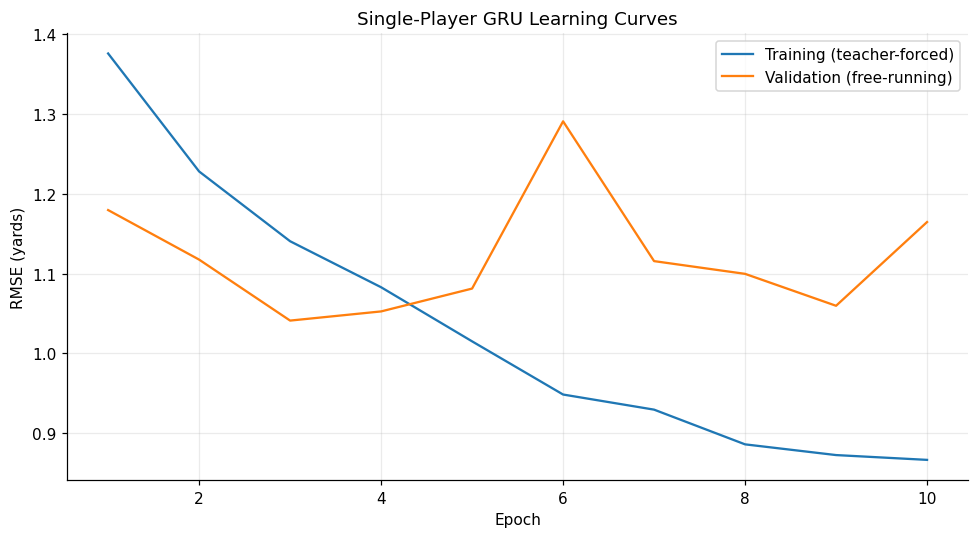

Best validation RMSE: 1.0410014584626086


In [25]:
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LR,
    weight_decay=1e-5
)

CLIP = 1.0

learning_history = []
best_valid_rmse = float("inf")
best_state = None
stale = 0

for epoch in range(1, MAX_EPOCHS + 1):

    train_rmse = train(
        model,
        train_loader,
        optimizer,
        CLIP,
        teacher_forcing_ratio=TEACHER_FORCING_RATIO
    )

    valid_rmse = evaluate(model, val_loader)

    learning_history.append({
        "epoch": epoch,
        "train_rmse": train_rmse,
        "val_rmse": valid_rmse
    })

    print(
        f"Epoch {epoch:02d} | "
        f"Train RMSE: {train_rmse:.4f} | "
        f"Val RMSE: {valid_rmse:.4f}"
    )

    if valid_rmse < best_valid_rmse - 1e-5:

        best_valid_rmse = valid_rmse
        best_state = copy.deepcopy(model.state_dict())

        torch.save(best_state, MODEL_PATH)
        stale = 0

    else:

        stale += 1

        if stale >= PATIENCE:
            print("Early stopping.")
            break

model.load_state_dict(best_state)

learning_df = pd.DataFrame(learning_history)

fig, ax = plt.subplots(figsize=(9, 5))

ax.plot(
    learning_df["epoch"],
    learning_df["train_rmse"],
    label="Training (teacher-forced)"
)

ax.plot(
    learning_df["epoch"],
    learning_df["val_rmse"],
    label="Validation (free-running)"
)

ax.set(
    xlabel="Epoch",
    ylabel="RMSE (yards)",
    title="Single-Player GRU Learning Curves"
)

ax.legend()
plt.tight_layout()

save_figure(fig, "gru_learning_curves.png")
plt.show()

print("Best validation RMSE:", best_valid_rmse)

In [26]:
@torch.no_grad()
def score_models(model, loader):

    model.eval()
    chunks = []

    for batch in loader:

        pred = model(
            batch["history"].to(DEVICE),
            batch["history_lengths"],
            batch["static"].to(DEVICE),
            batch["velocity"].to(DEVICE),
            batch["horizon"]
        ).cpu().numpy()

        truth = batch["target"].numpy()
        mask = batch["mask"].numpy().astype(bool)
        velocity = batch["velocity"].numpy()

        for i, info in enumerate(batch["metadata"]):

            valid_idx = np.flatnonzero(mask[i])

            if len(valid_idx) == 0:
                continue

            steps = valid_idx + 1

            # Constant-velocity predictions
            cv = velocity[i][None, :] * steps[:, None]

            chunks.append(pd.DataFrame({
                **info,
                "frame_id": steps,
                "actual_x": truth[i, valid_idx, 0],
                "actual_y": truth[i, valid_idx, 1],
                "gru_x": pred[i, valid_idx, 0],
                "gru_y": pred[i, valid_idx, 1],
                "cv_x": cv[:, 0],
                "cv_y": cv[:, 1]
            }))

    return pd.concat(chunks, ignore_index=True)


def score_summary(frames, prefix):

    dx = frames[f"{prefix}_x"] - frames["actual_x"]
    dy = frames[f"{prefix}_y"] - frames["actual_y"]

    squared_xy = dx**2 + dy**2
    distance = np.sqrt(squared_xy)

    # FDE uses the final valid frame for each trajectory
    final_idx = frames.groupby(
        PLAYER_KEYS, sort=False
    )["frame_id"].idxmax()

    return {
        "RMSE": np.sqrt(squared_xy.sum() / (2 * len(frames))),
        "ADE": distance.mean(),
        "FDE": distance.loc[final_idx].mean(),
        "Frames": len(frames),
        "Trajectories": len(final_idx)
    }


val_predictions = score_models(model, val_loader)

comparison = pd.DataFrame([
    {
        "Model": "Constant Velocity",
        **score_summary(val_predictions, "cv")
    },
    {
        "Model": "Single-Player GRU",
        **score_summary(val_predictions, "gru")
    }
])

print("Validation performance (yards)")
display(comparison.round(4))


Validation performance (yards)


,Model,RMSE,ADE,FDE,Frames,Trajectories
0,Constant Velocity,1.7274,1.5310,2.9119,95156,7464
1,Single-Player GRU,1.0410,0.8909,1.7023,95156,7464


,Role,Model,RMSE,ADE,FDE,Frames,Trajectories
0,Defensive Coverage,Constant Velocity,1.8399,1.6470,3.1718,68609,5211
1,Defensive Coverage,Single-Player GRU,1.1228,0.9683,1.8597,68609,5211
2,Targeted Receiver,Constant Velocity,1.3954,1.2311,2.3108,26547,2253
3,Targeted Receiver,Single-Player GRU,0.7915,0.6909,1.3382,26547,2253


Saved: /sfs/gpfs/tardis/home/jfq7bg/personal/DS_6050/DS-6050_Group_10/eda_figures/gru_role_horizon_comparison.png


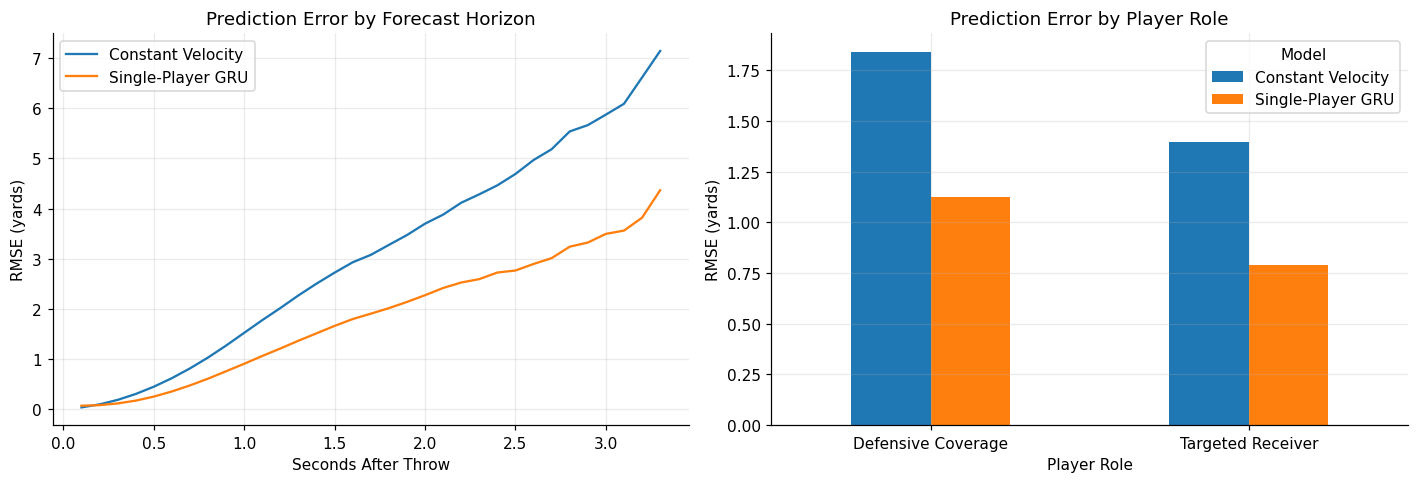

In [27]:
# Role comparison
role_results = []

for role, subset in val_predictions.groupby("role"):

    for name, prefix in [
        ("Constant Velocity", "cv"),
        ("Single-Player GRU", "gru")
    ]:

        role_results.append({
            "Role": role,
            "Model": name,
            **score_summary(subset, prefix)
        })

role_breakdown = pd.DataFrame(role_results)

display(role_breakdown.round(4))


# Forecast-horizon comparison
horizon_results = []

for step, subset in val_predictions.groupby("frame_id"):

    for name, prefix in [
        ("Constant Velocity", "cv"),
        ("Single-Player GRU", "gru")
    ]:

        dx = subset[f"{prefix}_x"] - subset["actual_x"]
        dy = subset[f"{prefix}_y"] - subset["actual_y"]

        squared_error = dx**2 + dy**2

        horizon_results.append({
            "Frame": step,
            "Seconds": step / FPS,
            "Model": name,
            "RMSE": np.sqrt(squared_error.mean() / 2),
            "ADE": np.sqrt(squared_error).mean(),
            "Frames": len(subset)
        })

horizon_breakdown = pd.DataFrame(horizon_results)


fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

# Error by horizon
for name, group in horizon_breakdown.groupby("Model"):

    axes[0].plot(
        group["Seconds"],
        group["RMSE"],
        label=name
    )

axes[0].set(
    xlabel="Seconds After Throw",
    ylabel="RMSE (yards)",
    title="Prediction Error by Forecast Horizon"
)

axes[0].legend()


# Error by role
focus = role_breakdown[
    role_breakdown["Role"].isin([
        "Targeted Receiver",
        "Defensive Coverage"
    ])
]

role_plot = focus.pivot(
    index="Role",
    columns="Model",
    values="RMSE"
)

role_plot.plot.bar(ax=axes[1], rot=0)

axes[1].set(
    xlabel="Player Role",
    ylabel="RMSE (yards)",
    title="Prediction Error by Player Role"
)

plt.tight_layout()
save_figure(fig, "gru_role_horizon_comparison.png")
plt.show()
